In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense


In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In [2]:

# Step 1: Load and inspect the dataset
df = pd.read_csv("Student_Performance.csv")
print("Dataset shape:", df.shape)
print(df.head())
print("Missing values:\n", df.isnull().sum())



Dataset shape: (10000, 6)
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
Missing values:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0


In [3]:
# Step 2: Create Pass/Fail labels (50 is an assumed cutoff)
df["Pass_Fail"] = (df["Performance Index"] >= 50).astype(int)
print("Pass/Fail counts:\n", df["Pass_Fail"].value_counts())



Pass/Fail counts:
 Pass_Fail
1    5909
0    4091
Name: count, dtype: int64


In [4]:
# Step 3: Encode text and separate features from target
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Performance Index", "Pass_Fail"])
y = df["Pass_Fail"]



In [5]:
# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)



In [6]:
# Step 5: Scale using statistics from training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [7]:
# Step 6: Build the Artificial Neural Network
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])



In [8]:
# Step 7: Compile and train the model
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()
history = model.fit(
    X_train_scaled, y_train, epochs=30, batch_size=32,
    validation_split=0.20, verbose=1
)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8306 - loss: 0.4578 - val_accuracy: 0.9519 - val_loss: 0.2566
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 991us/step - accuracy: 0.9636 - loss: 0.1793 - val_accuracy: 0.9644 - val_loss: 0.1295
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9702 - loss: 0.1058 - val_accuracy: 0.9663 - val_loss: 0.0952
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9725 - loss: 0.0817 - val_accuracy: 0.9650 - val_loss: 0.0820
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.9737 - loss: 0.0718 - val_accuracy: 0.9694 - val_loss: 0.0770
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9739 - loss: 0.0666 - val_accuracy: 0.9663 - val_loss: 0.0761
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9737 - loss: 0.0641 - val_accuracy: 0.9675 - val_loss: 0.0745
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9739 - loss: 0.0622 - val_accuracy

In [9]:
# Step 8: Make predictions on the test data
probabilities = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)




In [10]:
# Step 9: Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision (Pass):", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall (Pass):", round(recall_score(y_test, y_pred, zero_division=0), 3))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"], zero_division=0))



Accuracy: 97.5 %
Precision (Pass): 0.972
Recall (Pass): 0.986
Confusion Matrix:
 [[ 785   33]
 [  17 1165]]
              precision    recall  f1-score   support

        Fail       0.98      0.96      0.97       818
        Pass       0.97      0.99      0.98      1182

    accuracy                           0.97      2000
   macro avg       0.98      0.97      0.97      2000
weighted avg       0.98      0.97      0.97      2000



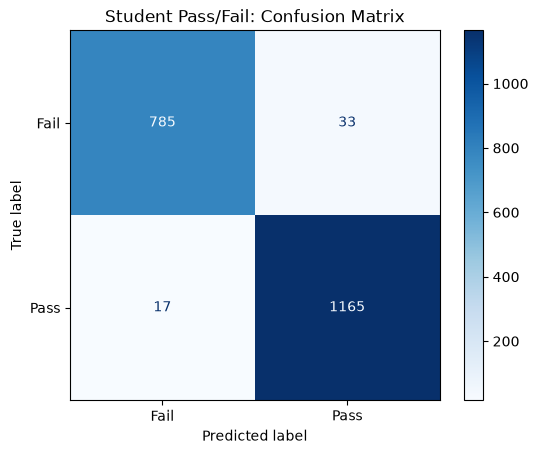

In [11]:
# Step 10: Plot confusion matrix
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Student Pass/Fail: Confusion Matrix")
plt.show()



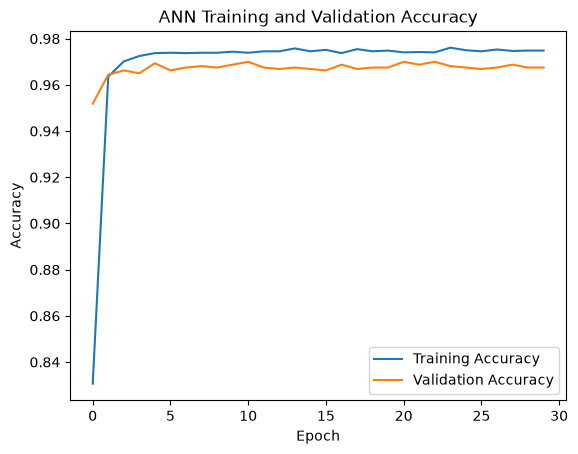

In [12]:
# Step 11: Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()